In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score)

In [2]:
df = pd.read_csv("wine_quality_cleaned.csv")
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7


In [3]:
print(df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality  
0      8.8        6  
1      9.5        6  
2     10.1        6 

In [4]:
df["quality_category"]=(df["quality"]>=7).astype(int)
print(df["quality_category"].value_counts())

quality_category
0    3838
1    1060
Name: count, dtype: int64


In [5]:
X=df.drop(["quality","quality_category"], axis=1)
y=df["quality_category"]

In [6]:
X_train, X_test, y_train, y_test=train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 3918
Testing records: 980


In [7]:
models = {"Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1)}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    results.append({"Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)})
results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.808163   0.622449  0.287736  0.393548
1        Decision Tree  0.832653   0.600840  0.674528  0.635556
2        Random Forest  0.890816   0.814371  0.641509  0.717678


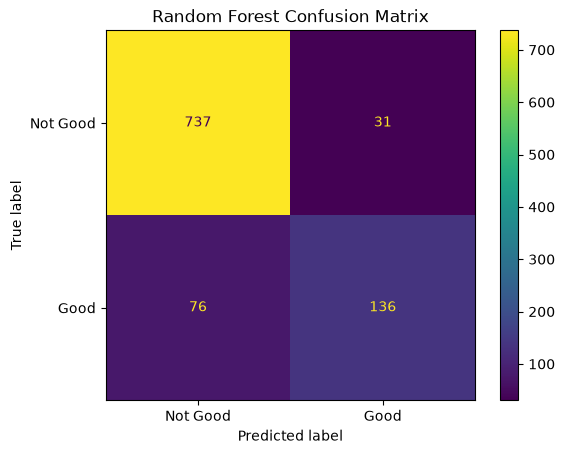

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

model=models["Random Forest"]
predictions=model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test,predictions,display_labels=["Not Good", "Good"])
plt.title("Random Forest Confusion Matrix")
plt.show()

In [9]:
probabilities=model.predict_proba(X_test)[:, 1]
print("ROC-AUC:",roc_auc_score(y_test, probabilities))

ROC-AUC: 0.9288061369889936


In [10]:
results_df.to_csv("classification_results.csv", index=False)

In [11]:
print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.808163   0.622449  0.287736  0.393548
1        Decision Tree  0.832653   0.600840  0.674528  0.635556
2        Random Forest  0.890816   0.814371  0.641509  0.717678


In [12]:
regression_results = results_df.copy()
print(regression_results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.808163   0.622449  0.287736  0.393548
1        Decision Tree  0.832653   0.600840  0.674528  0.635556
2        Random Forest  0.890816   0.814371  0.641509  0.717678


In [13]:
classification_results = results_df.copy()
print(classification_results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.808163   0.622449  0.287736  0.393548
1        Decision Tree  0.832653   0.600840  0.674528  0.635556
2        Random Forest  0.890816   0.814371  0.641509  0.717678


In [14]:
importance = pd.DataFrame({"Variable": X_train.columns,
    "Importance": models["Random Forest"].feature_importances_})
importance = importance.sort_values(by="Importance", ascending=False)
print(importance)

                Variable  Importance
10               alcohol    0.152775
7                density    0.124688
4              chlorides    0.090197
3         residual sugar    0.088251
1       volatile acidity    0.087986
5    free sulfur dioxide    0.084609
8                     pH    0.084348
6   total sulfur dioxide    0.079102
9              sulphates    0.075055
2            citric acid    0.067392
0          fixed acidity    0.065597


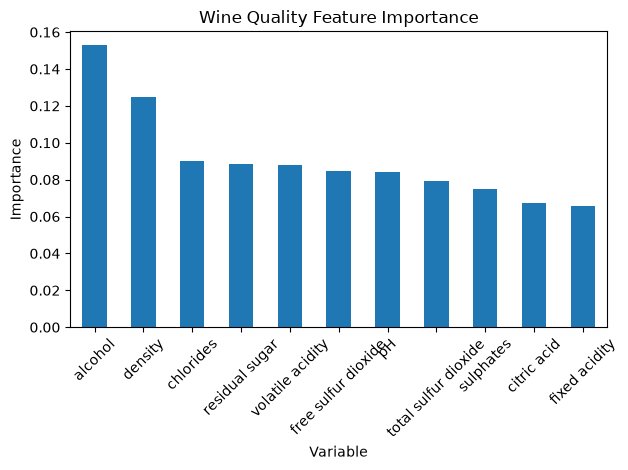

In [15]:
importance.plot(x="Variable", y="Importance",kind="bar", legend=False)
plt.title("Wine Quality Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import r2_score
model = models["Random Forest"]
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
print("Training R2:", r2_score(y_train, train_predictions))
print("Testing R2:", r2_score(y_test, test_predictions))

Training R2: 1.0
Testing R2: 0.3559601022012576
